# Deep Learning Project 1 — Cross-validated ensemble of 4 ResNets

Four copies of the ResNet from `DL_Project1_ResNet_CIFAR10.ipynb` (C = 80/160/320, B = 2/3/2, 4.80M parameters each) are
trained on **four different 45,000 / 5,000 train / validation splits** of the 50,000 labeled images, then combined:

| Submission | How the 4 predictions are combined |
|---|---|
| `submission_vote3of4.csv` | **Majority vote:** a label is taken when at least 3 of the 4 models agree; otherwise the averaged probabilities decide |
| `submission_soft.csv` | **Soft vote:** average the 4 models' probabilities, take the highest |
| `submission_boost.csv` | **Boosting-weighted vote (SAMME):** each model's vote is weighted by its held-out accuracy |
| `submission_model{k}.csv` | Each model on its own, for comparison |

### The 4 splits
The 50,000 images are split per class into disjoint blocks of 500 images (stratified, seed 42). Model *k* validates on block *k*
(5,000 images, 500 per class) and trains on the other 45,000. Fold 0 is **exactly** the validation split used by the earlier
notebooks, so its model is identical in setup to `student_baseline` and can be reused instead of retrained
(`reuse_kd_baseline` in the Config cell).

Every image is used for training by at least 3 of the 4 models, so the ensemble as a whole learns from all 50,000 images, and
each model still has an honest held-out accuracy.

**Parameter limit:** each model has 4.80M parameters (≤ 5M); the ensemble has 4 × 4.80M = 19.2M in total. Check the project
rules on whether the limit applies to each model or to the whole ensemble before submitting an ensemble as the final entry.

### How to run
Same as `DL_Project1_KD.ipynb`: put `data.zip` (or the cached `cifar_kaggle_uint8.npz`) in `WORK_DIR` and run all cells.
Training is resumable; finished models are skipped on re-runs.

## 1. Setup

In [1]:
import os, sys, time, math, json, copy, glob, zipfile, shutil, platform, random
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.transforms import v2

IN_COLAB = "google.colab" in sys.modules
IS_WINDOWS = platform.system() == "Windows"
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

assert torch.cuda.is_available(), "A CUDA device is required"
device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

AMP_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
props = torch.cuda.get_device_properties(0)
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | torchvision {torchvision.__version__}")
print(f"GPU: {props.name} | {props.total_memory / 1024**3:.1f} GB | CPU cores: {os.cpu_count()} | Colab: {IN_COLAB}")
print(f"Mixed precision dtype: {AMP_DTYPE}")

Python 3.11.3 | PyTorch 2.14.1+cu126 | torchvision 0.29.1+cu126
GPU: NVIDIA GeForce RTX 3070 Laptop GPU | 8.0 GB | CPU cores: 16 | Colab: False
Mixed precision dtype: torch.bfloat16


## 2. Config
Same student recipe as before (SGD + Nesterov, one-cycle LR peaking at 0.1, weight decay 5e-4, AutoAugment + Cutout,
label smoothing 0.1, EMA 0.999, 200 epochs). Model *k* uses seed `seed + k` for its initial weights and data order.

In [2]:
WORK_DIR = "/content/drive/MyDrive/dl_project1" if IN_COLAB else os.path.abspath(".")

CFG = dict(
    # ---- paths ----
    data_zip   = os.path.join(WORK_DIR, "data.zip"),
    data_dir   = "/content/data" if IN_COLAB else os.path.join(WORK_DIR, "data"),
    cache_file = os.path.join(WORK_DIR, "cifar_kaggle_uint8.npz"),      # shared with DL_Project1_KD.ipynb
    ckpt_dir   = os.path.join(WORK_DIR, "ens_checkpoints"),
    out_dir    = os.path.join(WORK_DIR, "ens_outputs"),
    kd_ckpt_dir = os.path.join(WORK_DIR, "kd_checkpoints"),               # where student_baseline was saved

    # ---- ensemble ----
    n_models = 4,
    fold_size = 5000,             # validation images per model (500 per class)
    seed = 42,
    vote_min = 3,                 # a label is accepted by the majority vote when at least this many models agree
    reuse_kd_baseline = True,     # fold 0 == the KD notebook's student_baseline split/seed/recipe -> reuse it if it exists

    # ---- model (unchanged) ----
    student = dict(channels=(80, 160, 320), blocks=(2, 3, 2)),     # 4.80M params

    # ---- optimisation ----
    batch_size = 128,
    lr = 0.1,
    momentum = 0.9,
    weight_decay = 5e-4,
    pct_start = 0.15,
    ema_decay = 0.999,
    epochs = 200,
    label_smoothing = 0.1,

    # ---- augmentation ----
    cutout = 16,
    aa_chunk = 16,

    # ---- system ----
    use_compile = not IS_WINDOWS, # torch.compile needs Triton (Linux)
    compile_mode = "default",
    ckpt_every = 5,
    smoke = False,                # True = 2 epochs on a small subset, to test the whole pipeline quickly
)
if CFG["smoke"]:
    CFG.update(epochs=2, ckpt_every=1, reuse_kd_baseline=False,
               ckpt_dir=CFG["ckpt_dir"] + "_smoke", out_dir=CFG["out_dir"] + "_smoke")
assert CFG["n_models"] * CFG["fold_size"] <= 50_000

os.makedirs(CFG["ckpt_dir"], exist_ok=True)
os.makedirs(CFG["out_dir"], exist_ok=True)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(CFG["seed"])
print(json.dumps({k: (str(v) if isinstance(v, (tuple, dict)) else v) for k, v in CFG.items()}, indent=2))

{
  "data_zip": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\data.zip",
  "data_dir": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\data",
  "cache_file": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\cifar_kaggle_uint8.npz",
  "ckpt_dir": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\ens_checkpoints",
  "out_dir": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\ens_outputs",
  "kd_ckpt_dir": "c:\\Users\\akhil\\Desktop\\Courses and Syllabus\\Deep learning\\Project1\\kd_checkpoints",
  "n_models": 4,
  "fold_size": 5000,
  "seed": 42,
  "vote_min": 3,
  "reuse_kd_baseline": true,
  "student": "{'channels': (80, 160, 320), 'blocks': (2, 3, 2)}",
  "batch_size": 128,
  "lr": 0.1,
  "momentum": 0.9,
  "weight_decay": 0.0005,
  "pct_start": 0.15,
  "ema_decay": 0.999,
  "epochs": 200,
  "label_smoothing": 0.1,
  "cutout": 16,
  "aa_chunk": 16,
  "us

## 3. Data and the 4 folds
The images are decoded once (or loaded from the cache) and kept on the device as `uint8`. Each class's 5,000 images are
shuffled once with seed 42 — the same shuffle the earlier notebooks used — and cut into blocks of 500: block *k* of every
class forms fold *k*'s validation set.

In [3]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def find_file(pattern, root):
    hits = glob.glob(os.path.join(root, "**", pattern), recursive=True)
    return hits[0] if hits else None

def load_pngs(folder, filenames):
    def _load(fn):
        with Image.open(os.path.join(folder, fn)) as im:
            return np.asarray(im.convert("RGB"), dtype=np.uint8)
    with ThreadPoolExecutor(32) as ex:
        return np.stack(list(ex.map(_load, filenames)))

t0 = time.time()
if os.path.exists(CFG["cache_file"]):
    d = np.load(CFG["cache_file"])
    x_all, y_all, x_test, test_ids = d["x_all"], d["y_all"], d["x_test"], d["test_ids"]
    print(f"Loaded cached arrays from {CFG['cache_file']}")
else:
    if find_file("train_labels.csv", CFG["data_dir"]) is None:
        zp = CFG["data_zip"]
        assert os.path.exists(zp), f"Upload the Kaggle data.zip to {zp}"
        if IN_COLAB:                       # extract from a local copy (much faster)
            shutil.copy(zp, "/content/data.zip"); zp = "/content/data.zip"
        print("Extracting", zp)
        with zipfile.ZipFile(zp) as z:
            z.extractall(CFG["data_dir"])
    labels_csv = find_file("train_labels.csv", CFG["data_dir"])
    root = os.path.dirname(labels_csv)
    train_df = pd.read_csv(labels_csv)
    test_df = pd.read_csv(os.path.join(root, "test.csv"))
    x_all = load_pngs(os.path.join(root, "train_images"), train_df["filename"])
    y_all = train_df["label"].to_numpy(dtype=np.int64)
    x_test = load_pngs(os.path.join(root, "test_images"), test_df["filename"])
    test_ids = test_df["id"].to_numpy()
    np.savez(CFG["cache_file"], x_all=x_all, y_all=y_all, x_test=x_test, test_ids=test_ids)
    print(f"Decoded PNGs and cached them to {CFG['cache_file']}")
print(f"{len(x_all)} train + {len(x_test)} test images in {time.time() - t0:.0f}s")

# Stratified disjoint folds. The per-class shuffle is the same as in the earlier notebooks, so fold 0 == their validation split.
rng = np.random.RandomState(CFG["seed"])
per_class = CFG["fold_size"] // 10
class_perm = [rng.permutation(np.where(y_all == c)[0]) for c in range(10)]
FOLDS = []
for k in range(CFG["n_models"]):
    val_idx = np.concatenate([p[k * per_class:(k + 1) * per_class] for p in class_perm])
    train_mask = np.ones(len(y_all), dtype=bool); train_mask[val_idx] = False
    train_idx = np.where(train_mask)[0]
    if CFG["smoke"]:
        train_idx, val_idx = train_idx[:2048], val_idx[::10]
    FOLDS.append((torch.from_numpy(train_idx).to(device), torch.from_numpy(val_idx).to(device)))

all_val = torch.cat([v for _, v in FOLDS])
assert len(torch.unique(all_val)) == len(all_val), "validation folds overlap"
times_trained = torch.zeros(len(y_all), dtype=torch.long)
for tr, _ in FOLDS:
    times_trained[tr.cpu()] += 1

def to_gpu_images(x):        # (N, 32, 32, 3) uint8 -> (N, 3, 32, 32) uint8 on the device
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)

X_ALL, Y_ALL = to_gpu_images(x_all), torch.from_numpy(y_all).to(device)
X_TEST = to_gpu_images(x_test)
for k, (tr, va) in enumerate(FOLDS):
    print(f"fold {k}: train {len(tr):,} | val {len(va):,} | val class counts {torch.bincount(Y_ALL[va], minlength=10).tolist()}")
print("images by number of models that train on them:",
      {int(n): int((times_trained == n).sum()) for n in torch.unique(times_trained)})

Decoded PNGs and cached them to c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\cifar_kaggle_uint8.npz
50000 train + 2000 test images in 19s
fold 0: train 45,000 | val 5,000 | val class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
fold 1: train 45,000 | val 5,000 | val class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
fold 2: train 45,000 | val 5,000 | val class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
fold 3: train 45,000 | val 5,000 | val class counts [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
images by number of models that train on them: {3: 20000, 4: 30000}


### Augmentation pipeline
Identical to `DL_Project1_KD.ipynb` — random crop with reflect padding 4, horizontal flip, AutoAugment (CIFAR-10 policy),
Cutout 16 — executed on whole batches at once.

In [4]:
MEAN = torch.tensor([0.4914, 0.4822, 0.4465], device=device).view(1, 3, 1, 1) * 255
STD = torch.tensor([0.2470, 0.2435, 0.2616], device=device).view(1, 3, 1, 1) * 255
AUTO_AUGMENT = v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10)

def _reflect(i, n):
    i = i.abs()
    return torch.where(i > n - 1, 2 * (n - 1) - i, i)

def random_crop_flip(x, pad=4):
    # Per-image random crop from a reflect-padded image + random horizontal flip, as one gather.
    B, C, H, W = x.shape
    dy = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    dx = torch.randint(-pad, pad + 1, (B, 1), device=x.device)
    rows = _reflect(torch.arange(H, device=x.device)[None] + dy, H)            # (B, H)
    cols = _reflect(torch.arange(W, device=x.device)[None] + dx, W)            # (B, W)
    flip = torch.rand(B, 1, device=x.device) < 0.5
    cols = torch.where(flip, cols.flip(1), cols)
    b = torch.arange(B, device=x.device)[:, None, None]
    return x[b, :, rows[:, :, None], cols[:, None, :]].permute(0, 3, 1, 2)      # (B, C, H, W)

def auto_augment(x):
    # One random AutoAugment sub-policy per chunk of images.
    return torch.cat([AUTO_AUGMENT(c) for c in x.split(CFG["aa_chunk"])])

def cutout(x, size):
    # Zero (= dataset mean after normalisation) one random size x size square per image.
    B, _, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    mask = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~mask).unsqueeze(1)

def normalize(x_uint8):
    return ((x_uint8.float() - MEAN) / STD).contiguous(memory_format=torch.channels_last)

def augment(x_uint8):
    x = auto_augment(random_crop_flip(x_uint8).contiguous())
    x = (x.float() - MEAN) / STD
    if CFG["cutout"]:
        x = cutout(x, CFG["cutout"])
    return x.contiguous(memory_format=torch.channels_last)

def train_batches(train_idx, batch_size):
    # One epoch of augmented batches from the given training indices (drop_last=True).
    perm = train_idx[torch.randperm(len(train_idx), device=device)]
    for i in range(0, len(perm) - batch_size + 1, batch_size):
        idx = perm[i:i + batch_size]
        yield augment(X_ALL[idx]), Y_ALL[idx]

## 4. Model
The same `ResNetCIFAR` as the original notebook: residual blocks `ReLU(S(x) + F(x))` with
`F = conv3x3 → BN → ReLU → conv3x3 → BN` and `S` = identity or a 1×1 strided projection, three stages, global average pooling
and a linear classifier.

In [5]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, conv_kernel=3, skip_kernel=1):
        super().__init__()
        p = conv_kernel // 2
        self.conv1 = nn.Conv2d(in_ch, out_ch, conv_kernel, stride, p, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, conv_kernel, 1, p, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, skip_kernel, stride, skip_kernel // 2, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x), inplace=True)


class ResNetCIFAR(nn.Module):
    def __init__(self, channels=(80, 160, 320), blocks=(2, 3, 2), conv_kernel=3, skip_kernel=1, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, channels[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], channels[0]
        for i, (ch, n) in enumerate(zip(channels, blocks)):
            for j in range(n):
                stride = 2 if (i > 0 and j == 0) else 1
                layers.append(BasicBlock(in_ch, ch, stride, conv_kernel, skip_kernel))
                in_ch = ch
        self.layers = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(in_ch, num_classes)
        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)
        for m in self.modules():
            if isinstance(m, BasicBlock):
                nn.init.zeros_(m.bn2.weight)         # zero-init residual branch

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.fc(torch.flatten(self.pool(x), 1))


def build_model(spec, seed):
    seed_everything(seed)
    return ResNetCIFAR(spec["channels"], spec["blocks"]).to(device).to(memory_format=torch.channels_last)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

P_STUDENT = n_params(build_model(CFG["student"], CFG["seed"]))
print(f"Each model: {P_STUDENT:,} parameters | ensemble of {CFG['n_models']}: {CFG['n_models'] * P_STUDENT:,} parameters")
assert P_STUDENT <= 5_000_000, "Model exceeds the 5M parameter limit!"

Each model: 4,798,810 parameters | ensemble of 4: 19,195,240 parameters


## 5. Training utilities

In [6]:
def autocast():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE)


class EMA:
    # Exponential moving average of weights and BN statistics, updated with fused foreach kernels.
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay

    @torch.no_grad()
    def update(self, model, step):
        w = 1 - min(self.decay, (1 + step) / (10 + step))
        torch._foreach_lerp_(list(self.module.parameters()), list(model.parameters()), w)
        for eb, mb in zip(self.module.buffers(), model.buffers()):
            if eb.dtype.is_floating_point:
                eb.lerp_(mb, w)
            else:
                eb.copy_(mb)


def make_optimizer(model, total_steps):
    decay, no_decay = [], []
    for p in model.parameters():
        (no_decay if p.ndim <= 1 else decay).append(p)      # no weight decay on BN parameters / biases
    groups = [{"params": decay, "weight_decay": CFG["weight_decay"]}, {"params": no_decay, "weight_decay": 0.0}]
    kw = dict(lr=CFG["lr"], momentum=CFG["momentum"], nesterov=True)
    try:
        opt = torch.optim.SGD(groups, fused=True, **kw)
    except (TypeError, RuntimeError):
        opt = torch.optim.SGD(groups, foreach=True, **kw)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=CFG["lr"], total_steps=total_steps, pct_start=CFG["pct_start"],
        anneal_strategy="cos", div_factor=25.0, final_div_factor=1e4)
    return opt, sched


@torch.no_grad()
def predict_probs(model, X, tta=False, bs=1000):
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x = normalize(X[i:i + bs])
        with autocast():
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(p)
    return torch.cat(out)


@torch.no_grad()
def evaluate(model, X, Y, tta=False):
    probs = predict_probs(model, X, tta)
    nll = F.nll_loss(torch.log(probs.clamp_min(1e-8)), Y).item()
    acc = (probs.argmax(1) == Y).float().mean().item() * 100
    return nll, acc, probs

In [7]:
def try_reuse_kd_baseline(name):
    """Fold 0 has the same split, seed and recipe as the KD notebook's student_baseline: copy it instead of retraining."""
    src_best = os.path.join(CFG["kd_ckpt_dir"], "student_baseline_best.pt")
    src_done = os.path.join(CFG["kd_ckpt_dir"], "student_baseline_done.json")
    if not (os.path.exists(src_best) and os.path.exists(src_done)):
        return False
    info = json.load(open(src_done))
    if info.get("epochs") != CFG["epochs"]:
        return False
    shutil.copy(src_best, os.path.join(CFG["ckpt_dir"], f"{name}_best.pt"))
    info.update(name=name, reused_from="kd_checkpoints/student_baseline")
    json.dump(info, open(os.path.join(CFG["ckpt_dir"], f"{name}_done.json"), "w"))
    print(f"[{name}] reusing the KD notebook's student_baseline (identical split, seed and recipe)")
    return True


def run_fold(k):
    """Train model k on fold k. Resumable; skipped if already finished."""
    name = f"model{k}"
    train_idx, val_idx = FOLDS[k]
    X_val, Y_val = X_ALL[val_idx], Y_ALL[val_idx]
    last_path = os.path.join(CFG["ckpt_dir"], f"{name}_last.pt")
    best_path = os.path.join(CFG["ckpt_dir"], f"{name}_best.pt")
    done_path = os.path.join(CFG["ckpt_dir"], f"{name}_done.json")
    model = build_model(CFG["student"], CFG["seed"] + k)

    if not os.path.exists(done_path) and k == 0 and CFG["reuse_kd_baseline"]:
        try_reuse_kd_baseline(name)
    if os.path.exists(done_path):
        info = json.load(open(done_path))
        model.load_state_dict(torch.load(best_path, map_location=device)["model"])
        print(f"[{name}] already trained - loaded best checkpoint (epoch {info['best_epoch']}, val {info['best_acc']:.2f}%)")
        return model, info

    epochs = CFG["epochs"]
    steps_per_epoch = len(train_idx) // CFG["batch_size"]
    opt, sched = make_optimizer(model, epochs * steps_per_epoch)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    ema = EMA(model, CFG["ema_decay"])
    start_epoch, step, best_acc, best_epoch, best_is_ema, history = 0, 0, 0.0, 0, False, []

    if os.path.exists(last_path):
        ck = torch.load(last_path, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); ema.module.load_state_dict(ck["ema"])
        opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, step, history = ck["epoch"], ck["step"], ck["history"]
        best_acc, best_epoch, best_is_ema = ck["best_acc"], ck["best_epoch"], ck["best_is_ema"]
        torch.set_rng_state(ck["rng_cpu"]); torch.cuda.set_rng_state(ck["rng_cuda"])
        print(f"[{name}] resumed at epoch {start_epoch}/{epochs} (best val so far {best_acc:.2f}%)")

    fwd = torch.compile(model, mode=CFG["compile_mode"]) if CFG["use_compile"] else model
    print(f"[{name}] {n_params(model):,} params | train {len(train_idx):,} / val {len(val_idx):,} | "
          f"{epochs} epochs x {steps_per_epoch} steps | seed {CFG['seed'] + k}"
          + (" | compiling (first epoch is slower)" if CFG["use_compile"] and start_epoch == 0 else ""))

    for epoch in range(start_epoch, epochs):
        model.train()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
        for x, y in train_batches(train_idx, CFG["batch_size"]):
            with autocast():
                out = fwd(x)
                loss = F.cross_entropy(out.float(), y, label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step); step += 1
            loss_sum += loss.detach() * x.size(0); correct += (out.argmax(1) == y).sum(); seen += x.size(0)
        epoch_time = time.time() - t0

        val_loss, val_acc, _ = evaluate(model, X_val, Y_val)
        ema_loss, ema_acc, _ = evaluate(ema.module, X_val, Y_val)
        history.append(dict(epoch=epoch + 1, lr=opt.param_groups[0]["lr"], train_loss=loss_sum.item() / seen,
                            train_acc=correct.item() / seen * 100, val_loss=val_loss, val_acc=val_acc,
                            ema_val_loss=ema_loss, ema_val_acc=ema_acc, time=epoch_time))

        if max(val_acc, ema_acc) > best_acc:
            best_acc, best_epoch, best_is_ema = max(val_acc, ema_acc), epoch + 1, ema_acc >= val_acc
            torch.save({"model": (ema.module if best_is_ema else model).state_dict(), "is_ema": best_is_ema,
                        "epoch": best_epoch, "val_acc": best_acc}, best_path)
        if (epoch + 1) % CFG["ckpt_every"] == 0 or epoch + 1 == epochs:
            torch.save({"model": model.state_dict(), "ema": ema.module.state_dict(), "opt": opt.state_dict(),
                        "sched": sched.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch + 1, "step": step,
                        "history": history, "best_acc": best_acc, "best_epoch": best_epoch, "best_is_ema": best_is_ema,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state()}, last_path)

        recent = [h["time"] for h in history[-5:]]
        eta_min = (epochs - epoch - 1) * (sum(recent) / len(recent)) / 60
        print(f"[{name}] ep {epoch + 1:3d}/{epochs} | lr {history[-1]['lr']:.2e} | train loss {history[-1]['train_loss']:.3f} "
              f"acc {history[-1]['train_acc']:5.2f}% | val loss {val_loss:.3f} acc {val_acc:5.2f}% | "
              f"EMA val loss {ema_loss:.3f} acc {ema_acc:5.2f}% | best {best_acc:5.2f}% | {epoch_time:.0f}s | ETA {eta_min:.0f} min")

    info = dict(name=name, params=n_params(model), epochs=epochs, best_acc=best_acc, best_epoch=best_epoch,
                best_is_ema=best_is_ema, train_minutes=sum(h["time"] for h in history) / 60, history=history)
    json.dump(info, open(done_path, "w"))
    pd.DataFrame(history).to_csv(os.path.join(CFG["out_dir"], f"{name}_history.csv"), index=False)
    model.load_state_dict(torch.load(best_path, map_location=device)["model"])
    print(f"[{name}] done in {info['train_minutes']:.1f} min - best val {best_acc:.2f}% at epoch {best_epoch} "
          f"({'EMA' if best_is_ema else 'raw'} weights)")
    del opt, sched, ema, fwd
    torch.cuda.empty_cache()
    return model, info

## 6. Train the 4 models
Each model is trained one after another; if training is interrupted, re-running this cell resumes the unfinished model and
skips the finished ones.

In [8]:
MODELS = {}
for k in range(CFG["n_models"]):
    model, info = run_fold(k)
    MODELS[f"model{k}"] = (model, info)

[model0] 4,798,810 params | train 45,000 / val 5,000 | 200 epochs x 351 steps | seed 42
[model0] ep   1/200 | lr 4.26e-03 | train loss 2.156 acc 21.39% | val loss 1.870 acc 31.60% | EMA val loss 1.853 acc 33.62% | best 33.62% | 24s | ETA 81 min
[model0] ep   2/200 | lr 5.05e-03 | train loss 2.058 acc 26.40% | val loss 1.748 acc 37.12% | EMA val loss 1.759 acc 36.26% | best 37.12% | 17s | ETA 68 min
[model0] ep   3/200 | lr 6.35e-03 | train loss 1.983 acc 30.32% | val loss 1.649 acc 38.96% | EMA val loss 1.649 acc 40.68% | best 40.68% | 17s | ETA 63 min
[model0] ep   4/200 | lr 8.15e-03 | train loss 1.935 acc 33.13% | val loss 1.555 acc 44.50% | EMA val loss 1.545 acc 45.30% | best 45.30% | 17s | ETA 61 min
[model0] ep   5/200 | lr 1.04e-02 | train loss 1.860 acc 37.13% | val loss 1.398 acc 48.98% | EMA val loss 1.414 acc 50.26% | best 50.26% | 17s | ETA 59 min
[model0] ep   6/200 | lr 1.32e-02 | train loss 1.790 acc 40.60% | val loss 1.362 acc 50.36% | EMA val loss 1.270 acc 55.10% | b

## 7. Held-out results per model
Each model is scored on **its own** 5,000 validation images, which it never trained on. Pooled together, the 4 folds give an
honest single-model accuracy over 20,000 images. (The ensemble itself cannot be scored this way: every validation image was
in the training data of the other 3 models.)

,seed,params,val loss (NLL),val acc %,val acc flip-TTA %,best epoch,weights,train time (min)
model,,,,,,,,
model0,42,4798810,0.1814,96.66,96.70,200,EMA,58.1
model1,43,4798810,0.1817,96.64,96.82,196,raw,57.2
model2,44,4798810,0.1728,96.92,96.98,198,raw,59.7
model3,45,4798810,0.1761,96.84,96.98,194,EMA,60.6


Pooled held-out accuracy (flip-TTA) over 20,000 images: 96.87% | spread between models: 96.70-96.98%


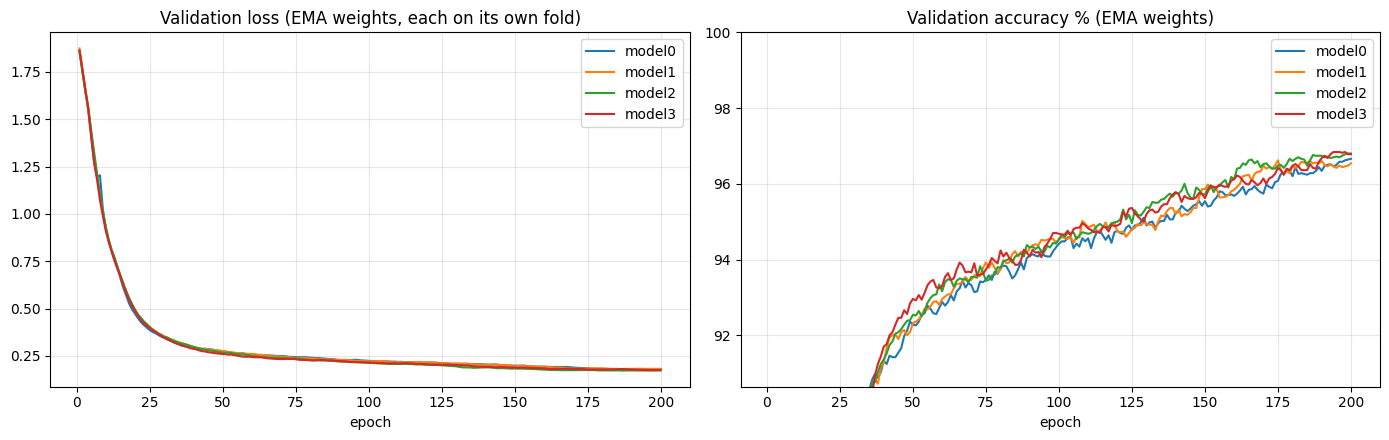

In [9]:
rows, OOF_CORRECT = [], []
for k, (name, (m, info)) in enumerate(MODELS.items()):
    _, val_idx = FOLDS[k]
    nll, acc, _ = evaluate(m, X_ALL[val_idx], Y_ALL[val_idx])
    nll_tta, acc_tta, probs = evaluate(m, X_ALL[val_idx], Y_ALL[val_idx], tta=True)
    OOF_CORRECT.append(probs.argmax(1) == Y_ALL[val_idx])
    rows.append({"model": name, "seed": CFG["seed"] + k, "params": n_params(m), "val loss (NLL)": round(nll, 4),
                 "val acc %": round(acc, 2), "val acc flip-TTA %": round(acc_tta, 2), "best epoch": info["best_epoch"],
                 "weights": "EMA" if info["best_is_ema"] else "raw", "train time (min)": round(info["train_minutes"], 1)})
results = pd.DataFrame(rows).set_index("model")
results.to_csv(os.path.join(CFG["out_dir"], "results.csv"))
display(results)
oof_acc = torch.cat(OOF_CORRECT).float().mean().item() * 100
print(f"Pooled held-out accuracy (flip-TTA) over {len(torch.cat(OOF_CORRECT)):,} images: {oof_acc:.2f}% "
      f"| spread between models: {results['val acc flip-TTA %'].min():.2f}-{results['val acc flip-TTA %'].max():.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name, (_, info) in MODELS.items():
    if not info.get("history"):
        continue
    h = pd.DataFrame(info["history"])
    ax[0].plot(h.epoch, h.ema_val_loss, label=name); ax[1].plot(h.epoch, h.ema_val_acc, label=name)
ax[0].set_title("Validation loss (EMA weights, each on its own fold)"); ax[1].set_title("Validation accuracy % (EMA weights)")
ax[1].set_ylim(max(results["val acc %"].min() - 6, 0), 100)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.savefig(os.path.join(CFG["out_dir"], "ens_curves.png"), dpi=150); plt.show()

## 8. Test predictions and the 3-of-4 majority vote
Each model predicts the 2,000 test images (flip-TTA). For every image:
* if **at least 3 of the 4 models** give the same label, that label is used;
* otherwise (2-2 or 2-1-1 splits, or all different), the label with the highest **averaged probability** is used.

In [10]:
TEST_PROBS = {}
for name, (m, _) in MODELS.items():
    TEST_PROBS[name] = predict_probs(m, X_TEST, tta=True)
    np.save(os.path.join(CFG["out_dir"], f"test_probs_{name}.npy"), TEST_PROBS[name].cpu().numpy())

def write_submission(labels, fname):
    labels = labels.cpu().numpy() if torch.is_tensor(labels) else labels
    path = os.path.join(CFG["out_dir"], fname)
    pd.DataFrame({"id": test_ids, "label": labels}).to_csv(path, index=False)
    print(f"Wrote {path} | predicted class counts {np.bincount(labels, minlength=10).tolist()}")
    return labels

SUBMISSIONS = {}
for name, p in TEST_PROBS.items():
    SUBMISSIONS[name] = write_submission(p.argmax(1), f"submission_{name}.csv")

P = torch.stack(list(TEST_PROBS.values()))                 # (models, images, classes)
preds = P.argmax(2)                                        # (models, images)
votes = F.one_hot(preds, 10).sum(0)                        # (images, classes) = number of models voting for each class
top_votes, top_label = votes.max(1)
soft_label = P.mean(0).argmax(1)
vote_label = torch.where(top_votes >= CFG["vote_min"], top_label, soft_label)

print(f"\nAgreement among the {CFG['n_models']} models on the test images:")
for n in range(CFG["n_models"], 0, -1):
    c = (top_votes == n).sum().item()
    print(f"  largest group = {n} models : {c:5d} images ({c / len(top_votes) * 100:5.1f}%)")
fallback = (top_votes < CFG["vote_min"]).sum().item()
print(f"Majority vote decided {len(top_votes) - fallback} images; {fallback} fell back to the averaged probabilities.")
SUBMISSIONS["vote3of4"] = write_submission(vote_label, "submission_vote3of4.csv")
SUBMISSIONS["soft"] = write_submission(soft_label, "submission_soft.csv")

Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_model0.csv | predicted class counts [173, 216, 209, 209, 203, 208, 179, 201, 199, 203]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_model1.csv | predicted class counts [169, 221, 204, 209, 193, 215, 181, 203, 207, 198]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_model2.csv | predicted class counts [173, 214, 204, 210, 195, 208, 183, 208, 204, 201]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_model3.csv | predicted class counts [173, 224, 202, 203, 194, 216, 180, 207, 203, 198]

Agreement among the 4 models on the test images:
  largest group = 4 models :  1773 images ( 88.6%)
  largest group = 3 models :   142 images (  7.1%)
  largest group = 2 models :    79 images (  4.0%)
  largest group = 1 models :     6 images (  0.3%)
Majority vote 

## 9. Boosting-weighted vote (SAMME)
**AdaBoost / SAMME** (Zhu et al., 2009) combines classifiers with weights
$\alpha_k = \log\frac{1 - e_k}{e_k} + \log(K - 1)$, where $e_k$ is model *k*'s error rate and $K = 10$ classes, so more accurate
models get a larger say. Here $e_k$ is each model's error on **its own held-out fold**, and the final label is
$\arg\max_c \sum_k \alpha_k \,[\text{model } k \text{ predicts } c]$ (ties broken by the averaged probabilities).

Full AdaBoost also trains the models **sequentially**, re-weighting the training images each model got wrong so the next
model focuses on them. That step does not carry over to these networks: each one fits its training images almost perfectly
(about 99.9% training accuracy), so there are almost no "wrong" training images to up-weight. The model weighting is the part
of boosting that applies; because the 4 models have similar held-out accuracy, the weights come out nearly equal and the
result is expected to be very close to the plain vote.

In [11]:
errors = torch.tensor([1 - results.loc[name, "val acc flip-TTA %"] / 100 for name in TEST_PROBS], device=device)
errors = errors.clamp(1e-4, 1 - 1e-4)
alphas = torch.log((1 - errors) / errors) + math.log(10 - 1)
weighted_votes = (F.one_hot(preds, 10).float() * alphas.view(-1, 1, 1)).sum(0)   # (images, classes)
boost_label = (weighted_votes + 1e-6 * P.mean(0)).argmax(1)                       # tiny soft term breaks exact ties

print("SAMME model weights:")
for name, e, a in zip(TEST_PROBS, errors.tolist(), alphas.tolist()):
    print(f"  {name}: held-out error {e * 100:.2f}% -> alpha {a:.3f} (share {a / alphas.sum().item() * 100:.1f}%)")
SUBMISSIONS["boost"] = write_submission(boost_label, "submission_boost.csv")

SAMME model weights:
  model0: held-out error 3.30% -> alpha 5.575 (share 24.8%)
  model1: held-out error 3.18% -> alpha 5.613 (share 24.9%)
  model2: held-out error 3.02% -> alpha 5.666 (share 25.2%)
  model3: held-out error 3.02% -> alpha 5.666 (share 25.2%)
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_boost.csv | predicted class counts [172, 221, 204, 208, 195, 209, 185, 203, 205, 198]


## 10. How different are the submissions?

In [12]:
names = list(SUBMISSIONS)
diff = pd.DataFrame([[int((SUBMISSIONS[a] != SUBMISSIONS[b]).sum()) for b in names] for a in names], index=names, columns=names)
print("Number of test images (out of 2,000) on which two submissions disagree:")
display(diff)

summary = {
    "architecture": f"ResNet, N=3, C={CFG['student']['channels']}, B={CFG['student']['blocks']}, F=3, K=1, global avg pool",
    "params_per_model": P_STUDENT,
    "n_models": CFG["n_models"],
    "ensemble_params": CFG["n_models"] * P_STUDENT,
    "pooled_heldout_acc_flip_tta": round(oof_acc, 2),
    "per_model": results.reset_index().to_dict(orient="records"),
    "samme_alphas": [round(a, 4) for a in alphas.tolist()],
    "vote_fallback_images": fallback,
}
with open(os.path.join(CFG["out_dir"], "ens_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=str)

print(f"\nEach model: {P_STUDENT:,} parameters | ensemble: {CFG['n_models'] * P_STUDENT:,} parameters")
print(f"Single-model held-out accuracy (pooled over 4 folds, flip-TTA): {oof_acc:.2f}%")
print("Submissions:", ", ".join(f"submission_{n}.csv" for n in names))

Number of test images (out of 2,000) on which two submissions disagree:


,model0,model1,model2,model3,vote3of4,soft,boost
model0,0,147,137,124,85,85,109
model1,147,0,140,136,100,102,84
model2,137,140,0,121,72,76,66
model3,124,136,121,0,66,68,59
vote3of4,85,100,72,66,0,4,32
soft,85,102,76,68,4,0,36
boost,109,84,66,59,32,36,0



Each model: 4,798,810 parameters | ensemble: 19,195,240 parameters
Single-model held-out accuracy (pooled over 4 folds, flip-TTA): 96.87%
Submissions: submission_model0.csv, submission_model1.csv, submission_model2.csv, submission_model3.csv, submission_vote3of4.csv, submission_soft.csv, submission_boost.csv


## 11. Test-time adaptation: BatchNorm recalibration
Every BatchNorm layer normalises its input with a running mean and variance that were measured on the **training** images.
If the test images differ in low-level statistics (brightness, contrast, colour, sharpness), those stored statistics no longer
match, and every layer's activations come out slightly off. **BN recalibration** re-measures the mean and variance on the
**test** images themselves, with no labels and no change to any learned weight (Schneider et al. 2020, *Improving robustness
against common corruptions by covariate shift adaptation*; Nado et al. 2020, *Evaluating prediction-time batch normalization
for robustness under covariate shift*).

For each of the 4 models: copy it, reset its BN statistics, run the 2,000 test images (plus their horizontal flips) through it
in training mode without gradients so the statistics are re-estimated, then predict with flip-TTA as before.

This uses the **unlabeled test images** to set the BN statistics — check that the project rules allow this before using these
submissions as a final entry.

This section only needs the already-trained models from the cells above (no retraining).

In [13]:
BN_BATCH = 500        # images per forward pass while re-estimating statistics (x2 with flips)

@torch.no_grad()
def bn_adapt(model, X, batch_size=BN_BATCH, use_flips=True, seed=0):
    """Copy of `model` whose BatchNorm running mean/var are re-estimated on the images X (labels unused, weights unchanged)."""
    m = copy.deepcopy(model)
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.reset_running_stats()
            mod.momentum = None          # cumulative average over all batches (not an exponential moving average)
    m.train()                            # in train mode BN normalises with batch statistics and accumulates them
    g = torch.Generator(device=X.device).manual_seed(seed)
    perm = torch.randperm(len(X), generator=g, device=X.device)
    for i in range(0, len(X), batch_size):
        x = normalize(X[perm[i:i + batch_size]])
        if use_flips:
            x = torch.cat([x, torch.flip(x, dims=[3])])
        with autocast():
            m(x)
    return m.eval()

# Sanity check on the held-out folds (labels available there):
#  * "val-BN": statistics re-estimated on the model's own validation fold -> same distribution as training, so accuracy
#    should stay about the same (shows the procedure itself does not damage the model);
#  * "test-BN": statistics from the test images, evaluated on the validation fold -> how different the test statistics are.
rows = []
for k, (name, (m, _)) in enumerate(MODELS.items()):
    _, val_idx = FOLDS[k]
    Xv, Yv = X_ALL[val_idx], Y_ALL[val_idx]
    _, acc_orig, _ = evaluate(m, Xv, Yv, tta=True)
    _, acc_valbn, _ = evaluate(bn_adapt(m, Xv), Xv, Yv, tta=True)
    _, acc_testbn, _ = evaluate(bn_adapt(m, X_TEST), Xv, Yv, tta=True)
    rows.append({"model": name, "val acc (train BN) %": round(acc_orig, 2), "val acc (val-BN) %": round(acc_valbn, 2),
                 "val acc (test-BN) %": round(acc_testbn, 2)})
bn_check = pd.DataFrame(rows).set_index("model")
display(bn_check)

,val acc (train BN) %,val acc (val-BN) %,val acc (test-BN) %
model,,,
model0,96.70,96.10,96.16
model1,96.82,96.14,96.08
model2,96.98,96.46,96.52
model3,96.98,96.24,96.28


In [14]:
# BN-recalibrated test predictions: one submission per model + the soft average of the 4
TEST_PROBS_BN = {}
for name, (m, _) in MODELS.items():
    m_bn = bn_adapt(m, X_TEST)
    TEST_PROBS_BN[name] = predict_probs(m_bn, X_TEST, tta=True)
    np.save(os.path.join(CFG["out_dir"], f"test_probs_bn_{name}.npy"), TEST_PROBS_BN[name].cpu().numpy())
    SUBMISSIONS[f"bn_{name}"] = write_submission(TEST_PROBS_BN[name].argmax(1), f"submission_bn_{name}.csv")
    del m_bn

P_BN = torch.stack(list(TEST_PROBS_BN.values()))
SUBMISSIONS["bn_soft"] = write_submission(P_BN.mean(0).argmax(1), "submission_bn_soft.csv")

# How many test labels did recalibration change?
pairs = [(f"bn_{n}", n) for n in TEST_PROBS] + [("bn_soft", "soft")]
changed = pd.DataFrame([{"submission": a, "compared with": b, "labels changed (of 2,000)": int((SUBMISSIONS[a] != SUBMISSIONS[b]).sum())}
                        for a, b in pairs]).set_index("submission")
display(changed)
conf_before = P.mean(0).max(1).values.mean().item()
conf_after = P_BN.mean(0).max(1).values.mean().item()
print(f"Mean ensemble confidence on the test images: {conf_before:.3f} (training BN) -> {conf_after:.3f} (test BN)")
print("New files:", ", ".join(f"submission_bn_{n}.csv" for n in TEST_PROBS), "+ submission_bn_soft.csv")

Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_bn_model0.csv | predicted class counts [167, 219, 209, 190, 194, 220, 182, 211, 209, 199]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_bn_model1.csv | predicted class counts [170, 219, 205, 199, 196, 218, 177, 210, 209, 197]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_bn_model2.csv | predicted class counts [170, 213, 203, 197, 194, 220, 190, 207, 210, 196]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_bn_model3.csv | predicted class counts [163, 224, 199, 199, 204, 216, 185, 207, 212, 191]
Wrote c:\Users\akhil\Desktop\Courses and Syllabus\Deep learning\Project1\ens_outputs\submission_bn_soft.csv | predicted class counts [172, 219, 204, 194, 197, 220, 183, 205, 209, 197]


,compared with,"labels changed (of 2,000)"
submission,,
bn_model0,model0,98
bn_model1,model1,116
bn_model2,model2,101
bn_model3,model3,110
bn_soft,soft,91


Mean ensemble confidence on the test images: 0.827 (training BN) -> 0.812 (test BN)
New files: submission_bn_model0.csv, submission_bn_model1.csv, submission_bn_model2.csv, submission_bn_model3.csv + submission_bn_soft.csv
